<a href="https://colab.research.google.com/github/elmehdimoufakkir/TP2_Apprentissage_Profond/blob/main/TP2_Apprentissage_Profond_Solution_ILIA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 — Apprentissage profond avec TensorFlow / Keras






In [2]:
# Décommenter cette ligne uniquement si les bibliothèques sont absentes :
# %pip install -U tensorflow numpy matplotlib scikit-learn


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Flatten, Dense, Dropout, LeakyReLU, Conv2D, MaxPooling2D
)
from tensorflow.keras.datasets import mnist, fashion_mnist
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Version TensorFlow :', tf.__version__)
print('Version NumPy :', np.__version__)
print('GPU détectés :', tf.config.list_physical_devices('GPU'))


Version TensorFlow : 2.21.0
Version NumPy : 2.1.3
GPU détectés : []


### Rappels théoriques

- **TensorFlow** est le moteur pour calculer et entraîner des modèles numériques ; **Keras** est l'API haut niveau servant à définir et entraîner facilement les réseaux de neurones.
- Un **neurone** réalise une combinaison pondérée des entrées, puis une activation. Une **couche Dense** relie tous ses neurones aux sorties de la couche précédente.
- **ReLU** renvoie $\max(0,x)$ ; **Softmax** convertit les scores des 10 classes en probabilités qui totalisent 1.
- La **loss** sert de signal à minimiser. L'**accuracy** mesure la proportion de bonnes prédictions.
- Une **époque** est un passage complet sur les exemples d'entraînement. La **rétropropagation** calcule les gradients et l'optimiseur les utilise pour mettre à jour les poids.

**Jeux de données et bonnes pratiques :** les ensembles de **validation** sont extraits des données d'entraînement ; le **test** demeure séparé pour l'évaluation finale. Le support utilise parfois directement le test en validation dans l'exercice 1 et dans l'augmentation de données ; le notebook corrige ce point pour éviter les biais d'évaluation.

---
# EXERCICE 1 — Reconnaissance de chiffres manuscrits : MNIST

**Objectif :** classifier les chiffres de **0 à 9** à partir d'images de **28 × 28 pixels**, en niveaux de gris, avec un modèle `Sequential` composé de couches denses.

## 1. Importation : réponses aux questions (page 3)

1. **TensorFlow vs Keras :** TensorFlow offre les opérations de calcul et d'apprentissage ; Keras simplifie la déclaration et l'entraînement des réseaux au moyen de `Sequential`, `Dense`, etc.
2. **`Flatten` :** transforme une image 2D `(28,28)` en vecteur 1D de **784 caractéristiques**, sans poids à apprendre.
3. **Version installée :** celle affichée par `tf.__version__` dans la première cellule de code ; elle dépend de la machine.
4. **`Sequential` et `Dense` :** `Sequential` empile les couches dans l'ordre ; `Dense` est une couche entièrement connectée.

## 2. Chargement et préparation de MNIST (page 3)

In [4]:
(x_train_mnist_raw, y_train_mnist), (x_test_mnist_raw, y_test_mnist) = mnist.load_data()

print('Dimensions entraînement :', x_train_mnist_raw.shape)
print('Dimensions test :', x_test_mnist_raw.shape)
print('Type des pixels avant normalisation :', x_train_mnist_raw.dtype)
print('Taille d’une image :', x_train_mnist_raw[0].shape)
print('Classes :', np.unique(y_train_mnist))

# Normalisation : [0, 255] → [0, 1]
x_train_mnist = x_train_mnist_raw.astype('float32') / 255.0
x_test_mnist = x_test_mnist_raw.astype('float32') / 255.0

print('Type après normalisation :', x_train_mnist.dtype)
print('Minimum / maximum :', x_train_mnist.min(), '/', x_train_mnist.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensions entraînement : (60000, 28, 28)
Dimensions test : (10000, 28, 28)
Type des pixels avant normalisation : uint8
Taille d’une image : (28, 28)
Classes : [0 1 2 3 4 5 6 7 8 9]
Type après normalisation : float32
Minimum / maximum : 0.0 / 1.0


**Réponses aux questions :**

1. On normalise les pixels de `[0,255]` vers `[0,1]` pour rendre les grandeurs comparables, faciliter l'optimisation numérique et, souvent, accélérer la convergence.
2. Une image a **28 × 28 pixels**. Le type d'origine est **`uint8`** ; après conversion et normalisation, le type est **`float32`**.
3. MNIST a **60 000 exemples d'entraînement** et **10 000 de test**, soit **70 000 images**.

## 3. Visualisation de quelques chiffres (page 4)

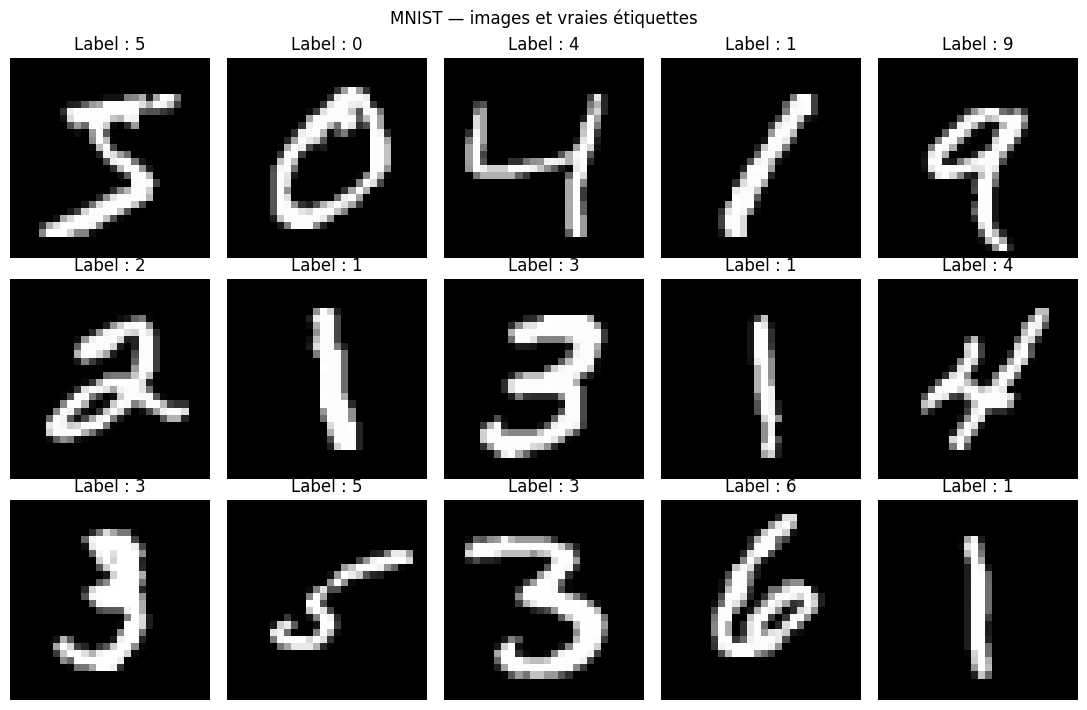

In [5]:
NB_IMAGES_MNIST = 15   # Modifier cette valeur pour afficher plus ou moins d'images
nb_colonnes = 5
nb_lignes = int(np.ceil(NB_IMAGES_MNIST / nb_colonnes))

plt.figure(figsize=(11, 2.4 * nb_lignes))
for i in range(NB_IMAGES_MNIST):
    plt.subplot(nb_lignes, nb_colonnes, i + 1)
    plt.imshow(x_train_mnist[i], cmap='gray')
    plt.title(f'Label : {y_train_mnist[i]}')
    plt.axis('off')
plt.suptitle('MNIST — images et vraies étiquettes')
plt.tight_layout()
plt.show()


**À faire et réponses :**

1. Les chiffres sont ceux figurant au-dessus de chaque image sous la forme **« Label : … »**. Vérifiez visuellement leur cohérence.
2. Changez `NB_IMAGES_MNIST` (et, si besoin, `nb_colonnes`) pour changer le nombre d'images affichées.
3. `cmap='gray'` représente les intensités sous la forme de **niveaux de gris**.
4. Cette exploration sert à vérifier que les images et les étiquettes sont correctes, à détecter d'éventuelles anomalies et à mieux comprendre les données avant l'entraînement.

## 4. Construction du réseau dense (pages 4–5)

In [6]:
modele_mnist = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax'),
])

modele_mnist.summary()
print('Nombre total de paramètres :', modele_mnist.count_params())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Nombre total de paramètres : 101770


**Réponses aux questions :**

1. **101 770 paramètres entraînables.** Calcul : `Flatten = 0`, première couche `Dense = (784 + 1) × 128 = 100 480`, sortie `Dense = (128 + 1) × 10 = 1 290`. Total : **101 770**.
2. La couche de sortie utilise **Softmax** pour fournir une probabilité pour chacune des dix classes.
3. **ReLU** s'utilise dans les couches cachées pour introduire de la non-linéarité ; **Softmax** s'utilise sur la sortie multiclasse pour normaliser les scores des classes.

## 5. Compilation du modèle (page 5)

In [7]:
modele_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
print('Modèle MNIST compilé.')


Modèle MNIST compilé.


**Réponses aux questions :**

1. **Optimiseur :** algorithme (ici **Adam**) qui modifie les poids pour minimiser la perte.
2. **Fonction de perte :** quantifie l'erreur entre vraies étiquettes et prédictions afin que l'optimiseur dispose d'un objectif à réduire.
3. **Changer la perte :** peut modifier l'objectif d'optimisation et la qualité de l'apprentissage. Avec des labels entiers `0–9`, `sparse_categorical_crossentropy` convient ; avec des vecteurs one-hot, on préfère `categorical_crossentropy`.
4. **Mauvais optimiseur :** apprentissage très lent, instable ou convergence insuffisante.
5. **Loss vs metrics :** `loss` guide les mises à jour des poids ; les `metrics` (ex. `accuracy`) servent à suivre et interpréter les performances, sans être nécessairement l'objectif optimisé.

## 6. Entraînement : 5 époques (page 6)

In [8]:
# Le TP original utilise le jeu de test comme validation.
# Ici, on réserve 10 % de x_train pour la validation : le test reste indépendant.
historique_mnist = modele_mnist.fit(
    x_train_mnist, y_train_mnist,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1,
)

print('Accuracy entraînement (dernière époque) :',
      f"{historique_mnist.history['accuracy'][-1]:.4f}")
print('Accuracy validation (dernière époque) :',
      f"{historique_mnist.history['val_accuracy'][-1]:.4f}")


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9217 - loss: 0.2730 - val_accuracy: 0.9620 - val_loss: 0.1289
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9646 - loss: 0.1199 - val_accuracy: 0.9703 - val_loss: 0.1014
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9758 - loss: 0.0816 - val_accuracy: 0.9732 - val_loss: 0.0905
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9822 - loss: 0.0598 - val_accuracy: 0.9745 - val_loss: 0.0882
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9875 - loss: 0.0444 - val_accuracy: 0.9742 - val_loss: 0.0887
Accuracy entraînement (dernière époque) : 0.9875
Accuracy validation (dernière époque) : 0.9742


**Observations et réponses :**

1. Une **époque** correspond à un parcours complet des données d'entraînement.
2. Le jeu de **validation** sert à observer la généralisation sur des exemples non utilisés pour modifier les poids ; cela aide à repérer le surapprentissage et à choisir des hyperparamètres.
3. Avec **50 époques**, la précision d'entraînement pourrait continuer à monter, mais la précision de validation peut plafonner ou se dégrader : risque de **surapprentissage**. Il faut expérimenter et utiliser éventuellement `EarlyStopping`.

L'évolution effective des deux précisions est affichée juste au-dessus par votre exécution.

## 7. Évaluation sur le test indépendant (page 6)

In [9]:
perte_test_mnist, precision_test_mnist = modele_mnist.evaluate(
    x_test_mnist, y_test_mnist, verbose=0
)
print(f'Précision finale MNIST sur 10 000 images de test : {precision_test_mnist:.4%}')
print(f'Loss finale MNIST sur le test : {perte_test_mnist:.4f}')


Précision finale MNIST sur 10 000 images de test : 97.3200%
Loss finale MNIST sur le test : 0.0900


**Réponses aux questions :**

1. La **précision finale** correspond à la valeur obtenue dans la cellule précédente. Elle dépend de l'entraînement ; elle n'est donc pas précisée à l'avance.
2. La précision d'entraînement est souvent meilleure, car les poids sont ajustés sur ces données ; le modèle peut mémoriser certaines particularités et moins bien généraliser sur de nouveaux exemples.
3. Pour réduire le **surapprentissage** : utiliser un jeu de validation, `Dropout`, de la régularisation, un modèle plus simple, `EarlyStopping`, ou davantage d'exemples appropriés.

## 8. Courbes d'apprentissage : accuracy et loss (pages 6–7)

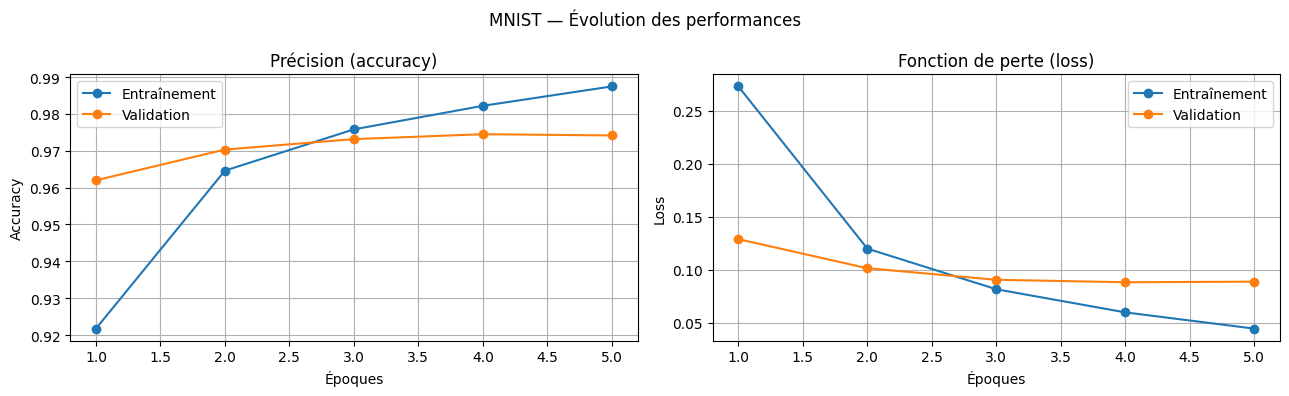

In [10]:
def afficher_courbes(historique, titre):
    # Affiche précision et perte, sur train et validation.
    h = historique.history
    epoques = range(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epoques, h['accuracy'], marker='o', label='Entraînement')
    axes[0].plot(epoques, h['val_accuracy'], marker='o', label='Validation')
    axes[0].set_title('Précision (accuracy)')
    axes[0].set_xlabel('Époques')
    axes[0].set_ylabel('Accuracy')
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(epoques, h['loss'], marker='o', label='Entraînement')
    axes[1].plot(epoques, h['val_loss'], marker='o', label='Validation')
    axes[1].set_title('Fonction de perte (loss)')
    axes[1].set_xlabel('Époques')
    axes[1].set_ylabel('Loss')
    axes[1].grid(True)
    axes[1].legend()
    fig.suptitle(titre)
    fig.tight_layout()
    plt.show()

afficher_courbes(historique_mnist, 'MNIST — Évolution des performances')


**Réponses aux questions :**

1. Normalement, les courbes de **précision** d'entraînement et de validation augmentent au début, tandis que les courbes de **perte** baissent. Leur tendance réelle dépend de l'exécution.
2. On soupçonne un **surapprentissage** lorsque l'accuracy d'entraînement monte, mais celle de validation stagne ou baisse ; en parallèle, la `val_loss` remonte tandis que la `loss` d'entraînement diminue.
3. Solutions : **EarlyStopping**, **Dropout**, régularisation L2 et ajustement du nombre d'époques.
4. Si les courbes divergent fortement, examiner le jeu de données, réduire la complexité ou le nombre d'époques, régulariser, puis comparer les métriques après réentraînement.

## 9. Prédictions et identification des erreurs (page 7)

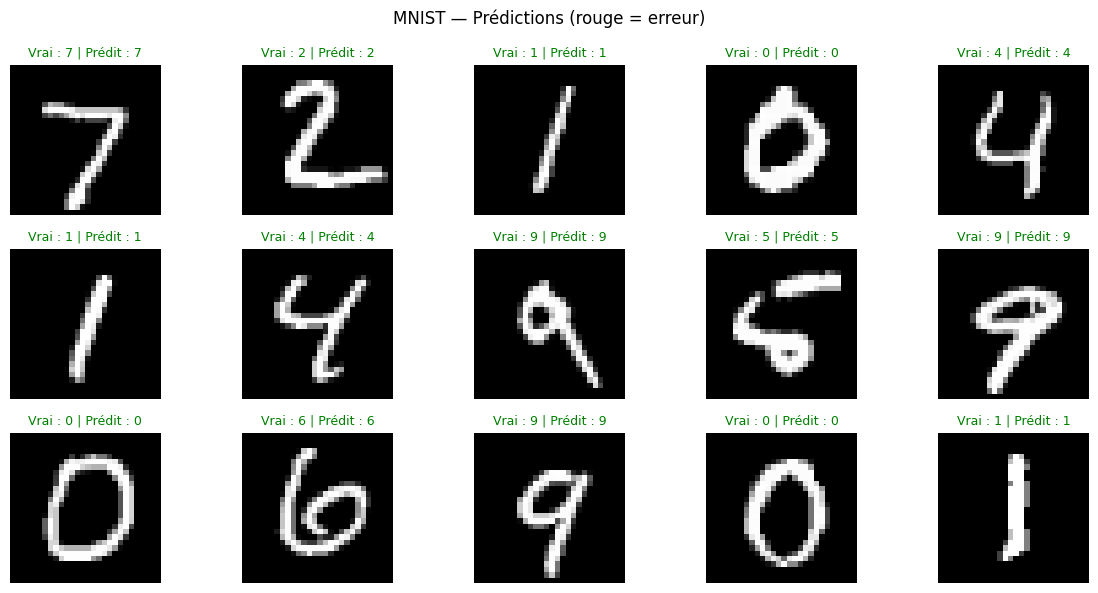

Nombre d’erreurs sur le test : 268
Taux d’erreur : 2.68%


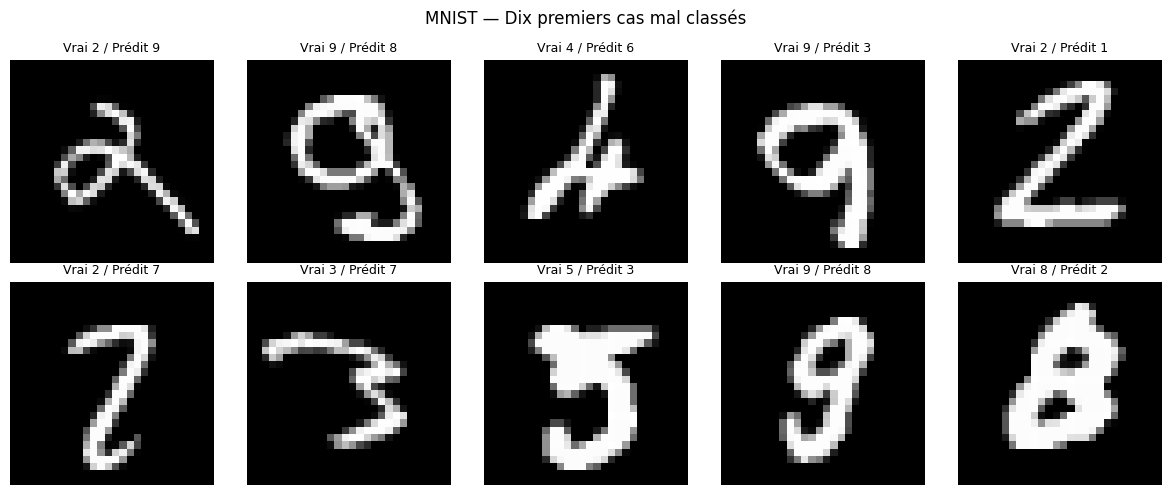

In [11]:
probas_mnist = modele_mnist.predict(x_test_mnist, verbose=0)
predictions_mnist = np.argmax(probas_mnist, axis=1)

plt.figure(figsize=(12, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test_mnist[i], cmap='gray')
    correct = predictions_mnist[i] == y_test_mnist[i]
    plt.title(f'Vrai : {y_test_mnist[i]} | Prédit : {predictions_mnist[i]}',
              color='green' if correct else 'red', fontsize=9)
    plt.axis('off')
plt.suptitle('MNIST — Prédictions (rouge = erreur)')
plt.tight_layout()
plt.show()

indices_erreurs_mnist = np.where(predictions_mnist != y_test_mnist)[0]
print('Nombre d’erreurs sur le test :', len(indices_erreurs_mnist))
print('Taux d’erreur :', f'{len(indices_erreurs_mnist)/len(y_test_mnist):.2%}')

if len(indices_erreurs_mnist):
    plt.figure(figsize=(12, 5))
    for j, idx in enumerate(indices_erreurs_mnist[:10]):
        plt.subplot(2, 5, j + 1)
        plt.imshow(x_test_mnist[idx], cmap='gray')
        plt.title(f'Vrai {y_test_mnist[idx]} / Prédit {predictions_mnist[idx]}', fontsize=9)
        plt.axis('off')
    plt.suptitle('MNIST — Dix premiers cas mal classés')
    plt.tight_layout()
    plt.show()


**Réponses aux questions :**

1. Les erreurs du modèle sont montrées dans la seconde grille (si elles existent) : leur nombre réel est calculé par le code.
2. Une erreur peut venir d'une écriture ambiguë, d'un chiffre inhabituel, d'un contraste insuffisant ou des limites de l'architecture dense.
3. Pour progresser : utiliser un **CNN**, qui préserve la structure spatiale des images, ou tester davantage de données, une augmentation pertinente et l'ajustement des hyperparamètres.

## Bilan demandé — Exercice 1 (page 8)

In [12]:
print('BILAN MNIST')
print('-----------')
print(f'Précision de test : {precision_test_mnist:.2%}')
print(f'Loss de test : {perte_test_mnist:.4f}')
print(f'Nombre de paramètres : {modele_mnist.count_params():,}')
print(f'Erreurs de classification : {len(indices_erreurs_mnist)} sur {len(y_test_mnist)}')


BILAN MNIST
-----------
Précision de test : 97.32%
Loss de test : 0.0900
Nombre de paramètres : 101,770
Erreurs de classification : 268 sur 10000


### Exemple d'analyse personnelle (8 lignes, à ajuster après exécution)

1. Le réseau dense convertit chaque image MNIST de 28 × 28 pixels en vecteur de 784 valeurs.
2. La première couche cachée comporte 128 neurones avec activation ReLU ; la sortie utilise Softmax.
3. L'entraînement sur cinq époques permet au modèle d'apprendre à reconnaître les chiffres manuscrits.
4. La précision de test est affichée dans le bilan et mesure la performance sur des images non vues.
5. Les courbes de précision et de perte permettent d'évaluer la progression de l'apprentissage.
6. Les mauvaises prédictions peuvent correspondre à des caractères visuellement ambigus.
7. L'une des difficultés possibles concerne la disponibilité de TensorFlow ou le téléchargement initial des données.
8. Pour améliorer les résultats, on peut étudier un CNN, le Dropout, l'augmentation de données et le réglage des hyperparamètres.

> **Pour le rapport :** joindre les deux courbes, une capture des prédictions, la précision affichée et vos observations effectives, en remplaçant les formulations générales par des constats issus de votre exécution.

---
# EXERCICE 2 — Classification de vêtements : Fashion-MNIST

**Objectif :** classifier **10 catégories d'articles de mode**, comparer un réseau dense **ANN**, quatre fonctions d'activation et un réseau **CNN**, puis analyser les confusions et la data augmentation.

## Étape 1 — Chargement et exploration (pages 8–9)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensions train : (60000, 28, 28)
Dimensions test : (10000, 28, 28)
Type avant normalisation : uint8
Classes détectées : [0 1 2 3 4 5 6 7 8 9]


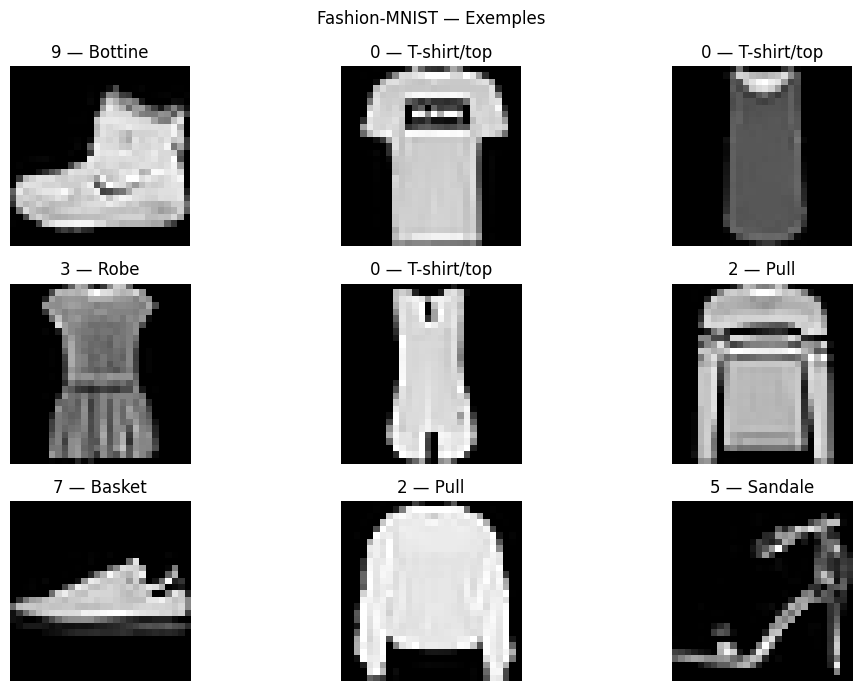

In [13]:
(X_train_fashion_raw, y_train_fashion), (X_test_fashion_raw, y_test_fashion) = fashion_mnist.load_data()

noms_classes = [
    'T-shirt/top', 'Pantalon', 'Pull', 'Robe', 'Manteau',
    'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine'
]

print('Dimensions train :', X_train_fashion_raw.shape)
print('Dimensions test :', X_test_fashion_raw.shape)
print('Type avant normalisation :', X_train_fashion_raw.dtype)
print('Classes détectées :', np.unique(y_train_fashion))

plt.figure(figsize=(11, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train_fashion_raw[i], cmap='gray')
    plt.title(f'{y_train_fashion[i]} — {noms_classes[y_train_fashion[i]]}')
    plt.axis('off')
plt.suptitle('Fashion-MNIST — Exemples')
plt.tight_layout()
plt.show()


**Réponse :** Fashion-MNIST contient **70 000 images en niveaux de gris** de **28 × 28 pixels** : **60 000 images** pour l'entraînement et **10 000** pour le test. Les valeurs initiales sont entières (`uint8`), les classes sont codées par des indices de 0 à 9 et les détails des vêtements restent limités par la faible résolution.

## Étape 2 — Normalisation et one-hot encoding (pages 9–10)

In [14]:
# Pixels réels dans [0, 1]
X_train_fashion = X_train_fashion_raw.astype('float32') / 255.0
X_test_fashion = X_test_fashion_raw.astype('float32') / 255.0

# 10 classes : label 3 → [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
y_train_fashion_cat = to_categorical(y_train_fashion, num_classes=10)
y_test_fashion_cat = to_categorical(y_test_fashion, num_classes=10)

# Même validation stratifiée pour comparer de façon juste ANN, activations, CNN et augmentation.
X_fit, X_val, y_fit_cat, y_val_cat = train_test_split(
    X_train_fashion,
    y_train_fashion_cat,
    test_size=0.2,
    stratify=y_train_fashion,
    random_state=SEED,
)
print('Train réel :', X_fit.shape, y_fit_cat.shape)
print('Validation :', X_val.shape, y_val_cat.shape)
print('Test :', X_test_fashion.shape, y_test_fashion_cat.shape)
print('Exemple de label one-hot :', y_train_fashion_cat[0])


Train réel : (48000, 28, 28) (48000, 10)
Validation : (12000, 28, 28) (12000, 10)
Test : (10000, 28, 28) (10000, 10)
Exemple de label one-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


**Réponses :**

1. **Normaliser** évite d'entraîner le réseau avec de grandes valeurs de pixels et facilite souvent la convergence de la descente de gradient.
2. Le **one-hot encoding** transforme la classe `k` en vecteur de 10 positions avec un `1` à la position `k`. Cet encodage est adapté à la perte **`categorical_crossentropy`**. Si l'on conservait des entiers, on pourrait choisir `sparse_categorical_crossentropy`.

**Remarque méthodologique :** `X_fit` (48 000 images) sert aux mises à jour des poids, `X_val` (12 000 images) sert à la validation ; `X_test_fashion` (10 000 images) reste réservé au test.

## Étape 3 — Construction du réseau dense ANN (pages 10–11)

In [15]:
modele_ann = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax'),
])
modele_ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
modele_ann.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7761 - loss: 0.6375 - val_accuracy: 0.8465 - val_loss: 0.4303
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8441 - loss: 0.4359 - val_accuracy: 0.8631 - val_loss: 0.3748
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8582 - loss: 0.3890 - val_accuracy: 0.8719 - val_loss: 0.3559
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8658 - loss: 0.3665 - val_accuracy: 0.8754 - val_loss: 0.3396
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8724 - loss: 0.3483 - val_accuracy: 0.8803 - val_loss: 0.3333
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8773 - loss: 0.3348 - val_accuracy: 0.8813 - val_loss: 0.3297
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8818 - loss: 0.3200 - val_accuracy: 0.8833 - val_loss: 0.3219
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8844 - loss: 0.3121 - val_accuracy: 0

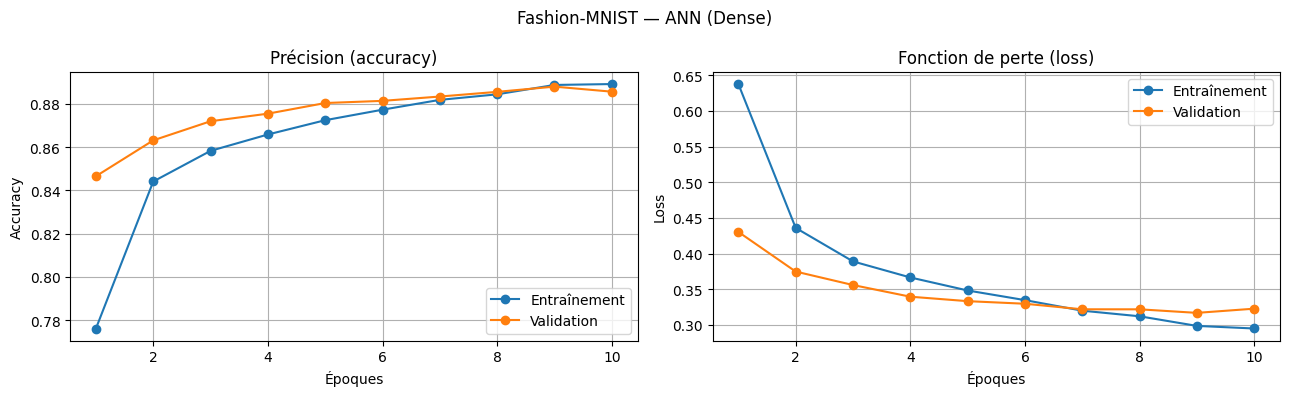

Précision ANN sur le jeu de test : 87.43%
Loss ANN sur le jeu de test : 0.3565


In [16]:
historique_ann = modele_ann.fit(
    X_fit, y_fit_cat,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val_cat),
    verbose=1,
)

afficher_courbes(historique_ann, 'Fashion-MNIST — ANN (Dense)')
perte_test_ann, precision_test_ann = modele_ann.evaluate(
    X_test_fashion, y_test_fashion_cat, verbose=0
)
print(f'Précision ANN sur le jeu de test : {precision_test_ann:.2%}')
print(f'Loss ANN sur le jeu de test : {perte_test_ann:.4f}')


**Réponses aux questions :**

1. **ReLU** est peu coûteuse et aide à apprendre des relations non linéaires. Dans les couches cachées, elle atténue certains problèmes de gradients très petits rencontrés avec sigmoïde et tanh.
2. **`accuracy`** est mesurée sur les exemples utilisés pour entraîner le modèle ; **`val_accuracy`** mesure la performance sur un jeu distinct non utilisé pour mettre les poids à jour.
3. **50 époques** peuvent apporter une amélioration au début, mais augmentent le temps d'exécution et le risque de surapprentissage. La décision doit se fonder sur les courbes de validation.

## Étape 4 — Comparaison : Sigmoid, Tanh, ReLU et LeakyReLU (page 12)

sigmoid    → validation accuracy : 87.31%
tanh       → validation accuracy : 88.13%
relu       → validation accuracy : 88.45%
LeakyReLU  → validation accuracy : 88.15%


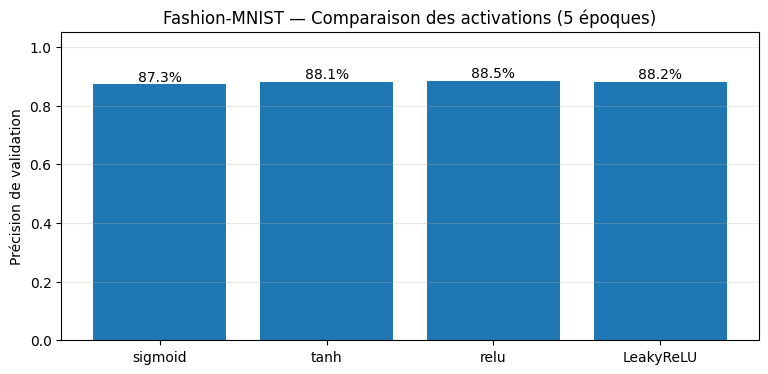

Meilleure activation dans cette expérience : relu


In [17]:
def creer_modele_activation(nom_activation):
    couches = [Input(shape=(28, 28)), Flatten(), Dense(128)]
    if nom_activation == 'LeakyReLU':
        couches.append(LeakyReLU(negative_slope=0.1))
    else:
        # Appliquée après Dense afin d'utiliser la même structure dans les quatre cas.
        couches.append(tf.keras.layers.Activation(nom_activation))
    couches.append(Dense(64))
    if nom_activation == 'LeakyReLU':
        couches.append(LeakyReLU(negative_slope=0.1))
    else:
        couches.append(tf.keras.layers.Activation(nom_activation))
    couches.append(Dense(10, activation='softmax'))

    reseau = Sequential(couches)
    reseau.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return reseau

resultats_activations = {}
historiques_activations = {}

for activation in ['sigmoid', 'tanh', 'relu', 'LeakyReLU']:
    tf.keras.utils.set_random_seed(SEED)
    reseau = creer_modele_activation(activation)
    historique = reseau.fit(
        X_fit, y_fit_cat,
        epochs=5,
        batch_size=128,
        validation_data=(X_val, y_val_cat),
        verbose=0,
    )
    score = historique.history['val_accuracy'][-1]
    resultats_activations[activation] = score
    historiques_activations[activation] = historique.history
    print(f'{activation:10s} → validation accuracy : {score:.2%}')

plt.figure(figsize=(9, 4))
barres = plt.bar(resultats_activations.keys(), resultats_activations.values())
for barre, valeur in zip(barres, resultats_activations.values()):
    plt.text(barre.get_x() + barre.get_width()/2, valeur, f'{valeur:.1%}',
             ha='center', va='bottom')
plt.ylim(0, 1.05)
plt.ylabel('Précision de validation')
plt.title('Fashion-MNIST — Comparaison des activations (5 époques)')
plt.grid(axis='y', alpha=0.3)
plt.show()

meilleure_activation = max(resultats_activations, key=resultats_activations.get)
print('Meilleure activation dans cette expérience :', meilleure_activation)


**Réponses aux questions :**

1. La **meilleure activation dans votre expérience** est celle affichée par `meilleure_activation`. Selon l'initialisation et les hyperparamètres, **ReLU** et **LeakyReLU** sont souvent compétitives ; on ne doit pas annoncer un vainqueur sans lire le graphe.
2. Les fonctions **sigmoïde** et **tanh** peuvent saturer pour de grandes valeurs absolues : leurs gradients deviennent petits, ce qui complique l'apprentissage des réseaux profonds.
3. **LeakyReLU** garde une petite pente pour les entrées négatives (`0.1` ici). Elle évite qu'un neurone avec des entrées négatives ait toujours un gradient nul, à la différence de ReLU standard dans cette région.

*Interprétation :* la comparaison fixe le jeu de validation, le nombre d'époques, la taille de batch et l'optimiseur pour rendre les résultats plus comparables.

## Étape 5 — Construction, entraînement et test d'un CNN (page 13)

In [18]:
# Ajout du canal « gris » : (N, 28, 28) → (N, 28, 28, 1)
X_fit_cnn = X_fit[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test_fashion[..., np.newaxis]

print('Dimensions pour CNN :', X_fit_cnn.shape, X_val_cnn.shape, X_test_cnn.shape)

def creer_cnn():
    reseau = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(10, activation='softmax'),
    ])
    reseau.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return reseau

tf.keras.utils.set_random_seed(SEED)  # Même initialisation de référence que le CNN augmenté
cnn = creer_cnn()
cnn.summary()


Dimensions pour CNN : (48000, 28, 28, 1) (12000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 110ms/step - accuracy: 0.7711 - loss: 0.6334 - val_accuracy: 0.8586 - val_loss: 0.3897
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.8580 - loss: 0.3934 - val_accuracy: 0.8812 - val_loss: 0.3303
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - accuracy: 0.8772 - loss: 0.3401 - val_accuracy: 0.8898 - val_loss: 0.3025
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 80s 108ms/step - accuracy: 0.8862 - loss: 0.3102 - val_accuracy: 0.8969 - val_loss: 0.2845
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.8951 - loss: 0.2859 - val_accuracy: 0.9007 - val_loss: 0.2757
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.9014 - loss: 0.2687 - val_accuracy: 0.9036 - val_loss: 0.2669
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 108ms/step - accuracy: 0.9065 - loss: 0.2523 - val_accuracy: 0.9062 - val_loss: 0.2588
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.9112 - loss: 0

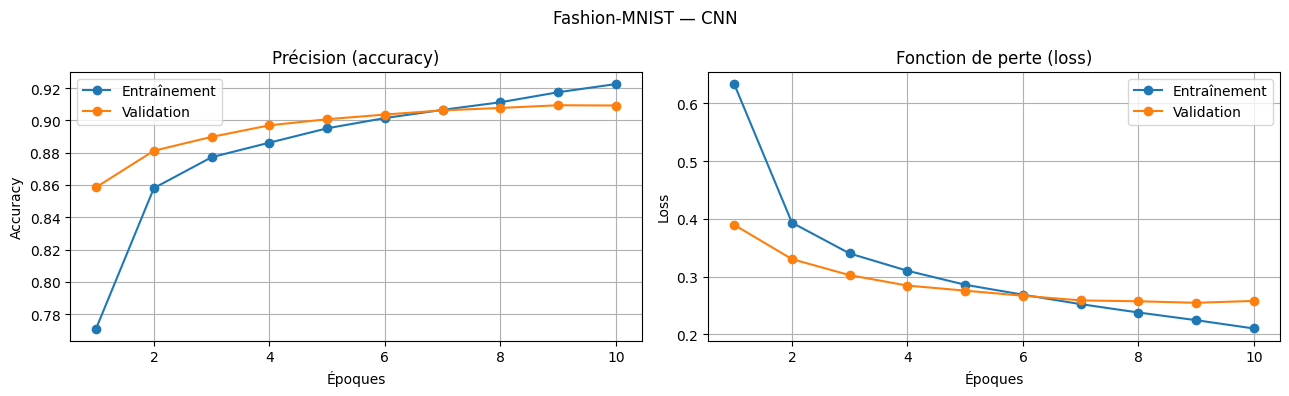

Précision CNN sur le test : 90.44%
Loss CNN sur le test : 0.2742
Gain CNN - ANN : +3.01% (points de précision)


In [19]:
historique_cnn = cnn.fit(
    X_fit_cnn, y_fit_cat,
    epochs=10,
    batch_size=128,
    validation_data=(X_val_cnn, y_val_cat),
    verbose=1,
)

afficher_courbes(historique_cnn, 'Fashion-MNIST — CNN')
perte_test_cnn, precision_test_cnn = cnn.evaluate(
    X_test_cnn, y_test_fashion_cat, verbose=0
)
print(f'Précision CNN sur le test : {precision_test_cnn:.2%}')
print(f'Loss CNN sur le test : {perte_test_cnn:.4f}')
print(f'Gain CNN - ANN : {(precision_test_cnn - precision_test_ann):+.2%} (points de précision)')


**Réponses aux questions :**

1. Un **ANN dense** (`Flatten` + `Dense`) considère rapidement les pixels comme un vecteur ; un **CNN** emploie des convolutions sur les régions locales de l'image et tient compte de leur disposition spatiale.
2. Le **CNN** obtient généralement de meilleures performances en vision, car ses filtres apprennent des motifs locaux (bords, textures, formes) et réutilisent leurs poids à diverses positions. L'écart réel est calculé ci-dessus.
3. **Pooling** (ici `MaxPooling2D`) réduit la taille des cartes de caractéristiques et les coûts de calcul. Il conserve les activations importantes et apporte une certaine tolérance à de petits déplacements.

## Étape 6 — Comparaison des modèles et matrice de confusion (page 14)

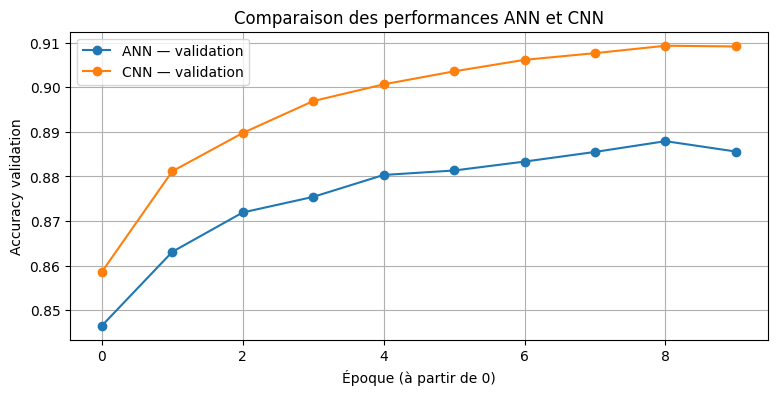

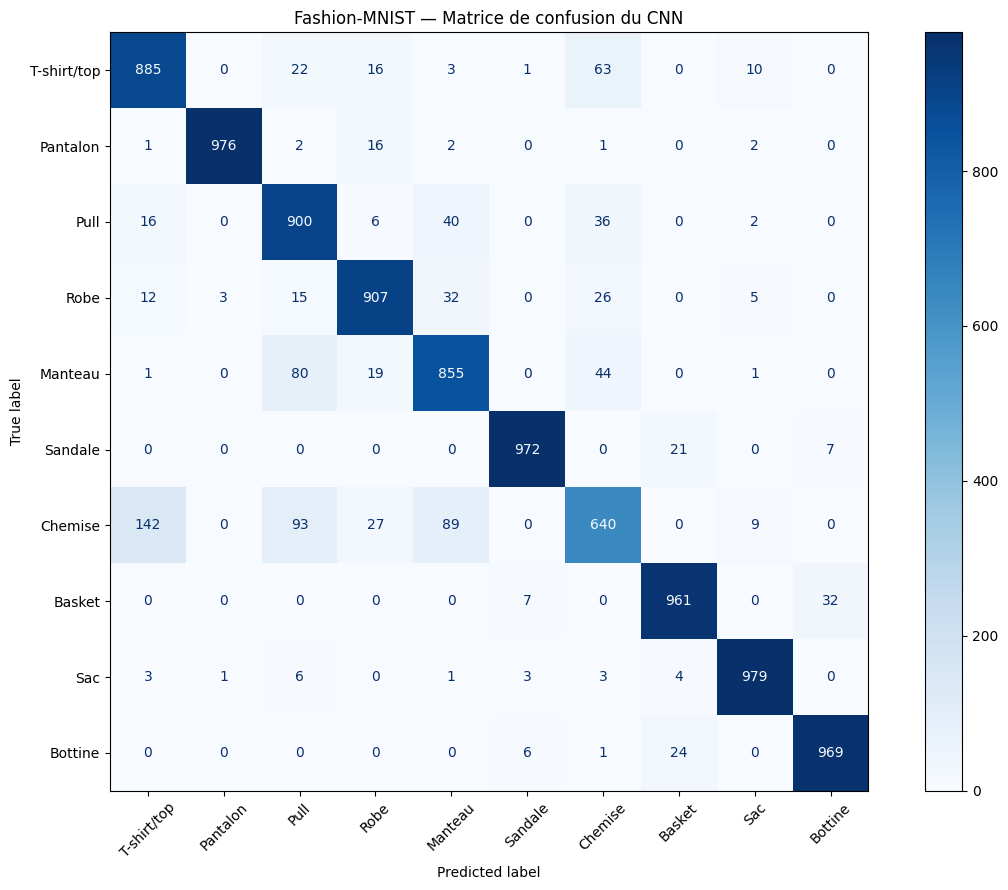

Paires de classes les plus souvent confondues (vrai → prédit) :
Chemise → T-shirt/top : 142 cas
Chemise → Pull : 93 cas
Chemise → Manteau : 89 cas
Manteau → Pull : 80 cas
T-shirt/top → Chemise : 63 cas


In [20]:
# Comparaison des courbes de précision de validation des deux architectures
plt.figure(figsize=(9, 4))
plt.plot(historique_ann.history['val_accuracy'], marker='o', label='ANN — validation')
plt.plot(historique_cnn.history['val_accuracy'], marker='o', label='CNN — validation')
plt.xlabel('Époque (à partir de 0)')
plt.ylabel('Accuracy validation')
plt.title('Comparaison des performances ANN et CNN')
plt.grid(True)
plt.legend()
plt.show()

probas_test_cnn = cnn.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(probas_test_cnn, axis=1)

fig, ax = plt.subplots(figsize=(12, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test_fashion,
    y_pred_cnn,
    display_labels=noms_classes,
    xticks_rotation=45,
    cmap='Blues',
    values_format='d',
    ax=ax,
)
ax.set_title('Fashion-MNIST — Matrice de confusion du CNN')
plt.tight_layout()
plt.show()

cm_cnn = confusion_matrix(y_test_fashion, y_pred_cnn)
cm_erreurs = cm_cnn.copy()
np.fill_diagonal(cm_erreurs, 0)
ordre = np.argsort(cm_erreurs, axis=None)[::-1]

print('Paires de classes les plus souvent confondues (vrai → prédit) :')
for indice in ordre[:5]:
    vraie, predite = np.unravel_index(indice, cm_erreurs.shape)
    if cm_erreurs[vraie, predite] == 0:
        break
    print(f'{noms_classes[vraie]} → {noms_classes[predite]} : '
          f'{cm_erreurs[vraie, predite]} cas')


**Réponses aux questions :**

1. Les **classes les plus confondues** sont calculées juste au-dessus, à partir des prédictions réellement obtenues. On peut fréquemment observer des confusions entre catégories visuellement proches comme **chemise / T-shirt**, **pull / manteau** ou **basket / bottine** ; vérifiez lesquelles apparaissent vraiment dans votre matrice.
2. Pour limiter ces confusions : augmenter le nombre d'exemples représentatifs, améliorer le CNN (filtres, couches, régularisation), essayer une augmentation de données raisonnable, régler la taille de batch et le learning rate, puis analyser les images mal classées.

## Étape 7 — Data augmentation (page 14)

La **data augmentation** crée, à la volée, des variantes d'images d'entraînement pour apprendre un modèle moins sensible aux petites variations visuelles. Le support propose **rotation (10°), zoom (10 %) et retournement horizontal**.

Pour comparer correctement, on entraînera un **nouveau CNN**, avec la même architecture que précédemment, plutôt que de prolonger le premier modèle. De plus, le jeu de test n'est **pas** utilisé comme validation pendant ce nouvel entraînement.

> *Note :* un retournement horizontal peut être adapté à de nombreuses images de vêtements, mais son intérêt doit être **mesuré** (il peut être inutile ou inadéquat selon le dataset). Pour le TP, on conserve le choix proposé.

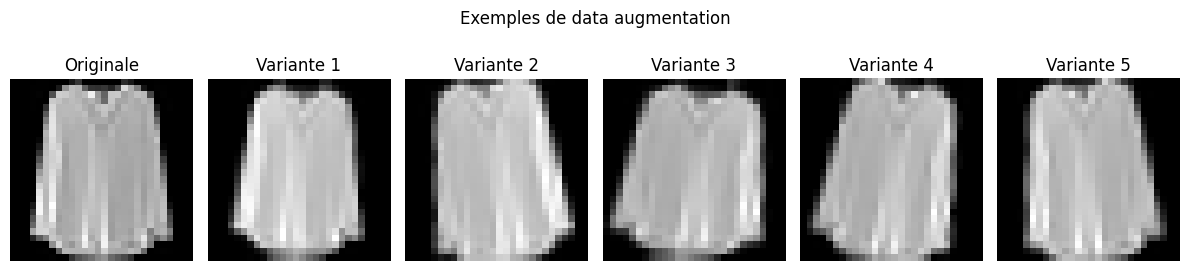

In [21]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
)

# Pas besoin de datagen.fit(...) : aucune statistique (ex. normalisation ZCA)
# dépendant de l'ensemble complet n'a été activée ici.
aperçu = datagen.flow(
    X_fit_cnn[:1], y_fit_cat[:1], batch_size=1,
    shuffle=False, seed=SEED,
)

plt.figure(figsize=(12, 3))
plt.subplot(1, 6, 1)
plt.imshow(X_fit_cnn[0, :, :, 0], cmap='gray')
plt.title('Originale')
plt.axis('off')
for i in range(5):
    image_aug, _ = next(aperçu)
    plt.subplot(1, 6, i + 2)
    plt.imshow(image_aug[0, :, :, 0], cmap='gray')
    plt.title(f'Variante {i + 1}')
    plt.axis('off')
plt.suptitle('Exemples de data augmentation')
plt.tight_layout()
plt.show()


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 56s 146ms/step - accuracy: 0.7240 - loss: 0.7544 - val_accuracy: 0.8344 - val_loss: 0.4521
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 144ms/step - accuracy: 0.8138 - loss: 0.5019 - val_accuracy: 0.8571 - val_loss: 0.3799
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 144ms/step - accuracy: 0.8342 - loss: 0.4471 - val_accuracy: 0.8596 - val_loss: 0.3811
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 144ms/step - accuracy: 0.8466 - loss: 0.4138 - val_accuracy: 0.8765 - val_loss: 0.3404
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 143ms/step - accuracy: 0.8546 - loss: 0.3903 - val_accuracy: 0.8771 - val_loss: 0.3388
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 144ms/step - accuracy: 0.8631 - loss: 0.3732 - val_accuracy: 0.8820 - val_loss: 0.3192
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 54s 143ms/step - accuracy: 0.8665 - loss: 0.3591 - val_accuracy: 0.8848 - val_loss: 0.3131
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 52s 139ms/step - accuracy: 0.8714 - loss: 0

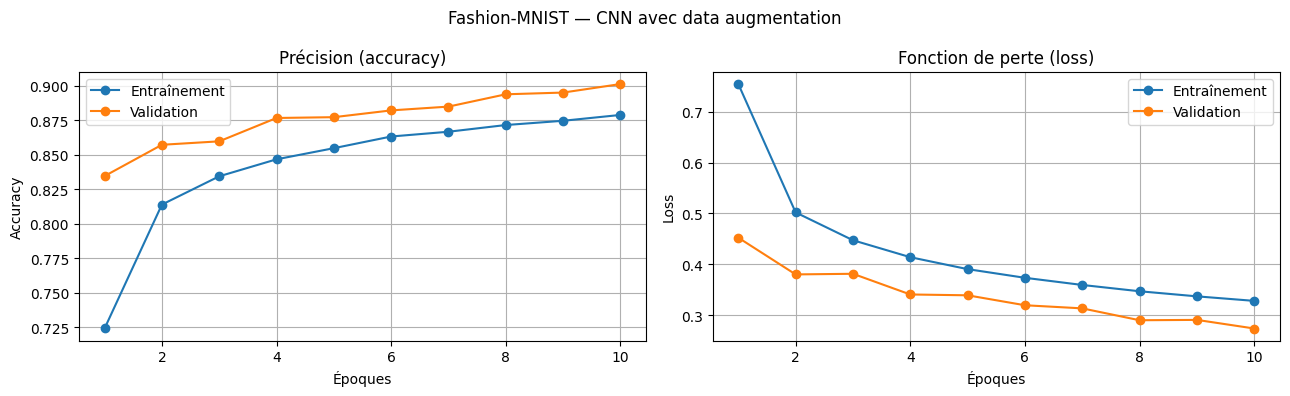

Précision test CNN sans augmentation : 90.44%
Précision test CNN avec augmentation : 89.40%
Différence : -1.04% (points de précision)


In [22]:
# Comparaison honnête : nouveau CNN entraîné sur les mêmes 48 000 exemples
# (augmentés à la volée), avec les mêmes 12 000 exemples de validation.
tf.keras.utils.set_random_seed(SEED)
cnn_augmente = creer_cnn()

historique_aug = cnn_augmente.fit(
    datagen.flow(X_fit_cnn, y_fit_cat, batch_size=128, seed=SEED),
    epochs=10,
    validation_data=(X_val_cnn, y_val_cat),
    verbose=1,
)

perte_test_aug, precision_test_aug = cnn_augmente.evaluate(
    X_test_cnn, y_test_fashion_cat, verbose=0
)

afficher_courbes(historique_aug, 'Fashion-MNIST — CNN avec data augmentation')
print(f'Précision test CNN sans augmentation : {precision_test_cnn:.2%}')
print(f'Précision test CNN avec augmentation : {precision_test_aug:.2%}')
print(f'Différence : {(precision_test_aug - precision_test_cnn):+.2%} (points de précision)')


**Réponses aux questions :**

1. L'intérêt de la **data augmentation** est de diversifier les exemples vus par le réseau sans collecter de nouvelles images ; elle peut aider à généraliser et à réduire le surapprentissage.
2. Pour Fashion-MNIST, des **petites rotations, translations et variations de zoom** peuvent être pertinentes, à condition de préserver l'identité de la classe. Le **retournement horizontal** doit être évalué expérimentalement. La cellule suivante compare précisément les performances avant/après augmentation ; il ne faut pas supposer qu'une transformation est toujours bénéfique.

## Bilan comparatif et conclusion — Exercice 2

In [23]:
comparaison = [
    ('ANN Dense', precision_test_ann, perte_test_ann),
    ('CNN', precision_test_cnn, perte_test_cnn),
    ('CNN + Data Augmentation', precision_test_aug, perte_test_aug),
]
print(f'{"Modèle":30s} | {"Accuracy test":>14s} | {"Loss test":>10s}')
print('-' * 64)
for nom, precision, perte in comparaison:
    print(f'{nom:30s} | {precision:14.2%} | {perte:10.4f}')

modele_gagnant = max(comparaison, key=lambda item: item[1])
print('\nMeilleur résultat observé sur le test :', modele_gagnant[0])
print('Ne pas choisir les hyperparamètres en fonction des résultats de test.')
print('Attention : les valeurs peuvent varier légèrement selon le matériel, '
      'les versions et les graines aléatoires.')


Modèle                         |  Accuracy test |  Loss test
----------------------------------------------------------------
ANN Dense                      |         87.43% |     0.3565
CNN                            |         90.44% |     0.2742
CNN + Data Augmentation        |         89.40% |     0.2970

Meilleur résultat observé sur le test : CNN
Ne pas choisir les hyperparamètres en fonction des résultats de test.
Attention : les valeurs peuvent varier légèrement selon le matériel, les versions et les graines aléatoires.


### Proposition d'analyse personnelle (à compléter avec vos chiffres)

- **Observations :** comparer les précisions `ANN`, `CNN` et `CNN + augmentation` affichées dans le tableau.
- **Activations :** relever sur l'histogramme laquelle de Sigmoid, Tanh, ReLU et LeakyReLU a le meilleur score de validation.
- **Erreurs :** citer les 2 à 3 paires de vêtements les plus confondues dans la matrice, et expliquer leur proximité visuelle.
- **Généralisation :** interpréter les écarts entre précision d'entraînement et de validation ; examiner la perte de validation.
- **Améliorations possibles :** plus de filtres ou de données, BatchNormalization, `EarlyStopping`, régularisation, réglage du learning rate et choix pertinent des transformations.

**Conclusion :** le TP montre que des couches denses suffisent pour construire un premier classificateur, mais que les convolutions sont mieux adaptées à la structure spatiale des images. Les performances exactes, leur écart et le bénéfice éventuel de l'augmentation sont ceux calculés lors de l'exécution, et non des valeurs garanties a priori.

---
## Références et consignes de remise

- **Support de TP :** *TP2 — Apprentissage Profond avec TensorFlow/Keras*, ENSA Fès, 14 pages, fourni par l'enseignant.
- **Datasets :** MNIST et Fashion-MNIST, accessibles directement via `tf.keras.datasets` ; aucun téléchargement Kaggle manuel n'est requis.
- **À remettre :** ce notebook avec ses cellules exécutées et leurs sorties visibles, les courbes d'accuracy/loss, les valeurs de précision, les prédictions, la matrice de confusion et une analyse personnelle.
- **En cas de manque de mémoire ou de temps :** réduire ponctuellement les époques de la comparaison des activations et du CNN pour explorer le code ; **revenir aux valeurs 5 et 10 du TP pour la version finale**.

*Le notebook est fourni non exécuté : lancez les cellules dans l'ordre sur une installation disposant de TensorFlow et d'un accès initial aux datasets.*